In [ ]:
#tiktok-posting-analysis

In [198]:
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
from patsy import dmatrix
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from sklearn.linear_model import LinearRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

warnings.filterwarnings("ignore")
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 50)

DATA = '../BIT3484/data/'
tiktok_csv = DATA + 'tiktok_data.csv'
tiktok_df = pd.read_csv(tiktok_csv)

In [199]:
print("Shape:",tiktok_df.shape)

Shape: (760, 10)


In [200]:
tiktok_df.head()

,id_video,duration_seconds,text_part,hashtags,human_time,author_followers,author_likes,id_sound,views,likes
0,1,13.0,А че такое?,"попугай, жако, попугайжако, говорящийпопугай, ...",2018-08-08 20:58:31,675900.0,7500000.0,7.028884e+18,144600000.0,4400000.0
1,2,9.0,Таксист в шоке😱 Inst: Andrey_Pryahin,NaN,2016-01-29 06:16:13,2300000.0,42600000.0,6.870179e+18,113300000.0,5300000.0
2,3,52.0,NaN,рекомендации,2018-12-30 09:24:42,58400.0,613400.0,7.052607e+18,105100000.0,505300.0
3,4,60.0,"Учитесь хитрить, как она 😄😉",NaN,2021-03-10 19:57:42,523900.0,11200000.0,6.984582e+18,96700000.0,3000000.0
4,5,16.0,телефонный пранк от говорящего ворона Карлушы,"пранк, шутка, говорящийворонкарлуша, воронгово...",2020-03-21 11:59:19,943700.0,16800000.0,7.052249e+18,139200000.0,5900000.0


In [201]:
tiktok_df = tiktok_df.drop(columns='text_part', errors='ignore')
tiktok_df.head()

#take out text_part as it is not necesssary

,id_video,duration_seconds,hashtags,human_time,author_followers,author_likes,id_sound,views,likes
0,1,13.0,"попугай, жако, попугайжако, говорящийпопугай, ...",2018-08-08 20:58:31,675900.0,7500000.0,7.028884e+18,144600000.0,4400000.0
1,2,9.0,NaN,2016-01-29 06:16:13,2300000.0,42600000.0,6.870179e+18,113300000.0,5300000.0
2,3,52.0,рекомендации,2018-12-30 09:24:42,58400.0,613400.0,7.052607e+18,105100000.0,505300.0
3,4,60.0,NaN,2021-03-10 19:57:42,523900.0,11200000.0,6.984582e+18,96700000.0,3000000.0
4,5,16.0,"пранк, шутка, говорящийворонкарлуша, воронгово...",2020-03-21 11:59:19,943700.0,16800000.0,7.052249e+18,139200000.0,5900000.0


In [202]:
tiktok_df = tiktok_df.drop(columns='hashtags', errors='ignore')
tiktok_df.head()

#take out hashtags as it is not necesssary

,id_video,duration_seconds,human_time,author_followers,author_likes,id_sound,views,likes
0,1,13.0,2018-08-08 20:58:31,675900.0,7500000.0,7.028884e+18,144600000.0,4400000.0
1,2,9.0,2016-01-29 06:16:13,2300000.0,42600000.0,6.870179e+18,113300000.0,5300000.0
2,3,52.0,2018-12-30 09:24:42,58400.0,613400.0,7.052607e+18,105100000.0,505300.0
3,4,60.0,2021-03-10 19:57:42,523900.0,11200000.0,6.984582e+18,96700000.0,3000000.0
4,5,16.0,2020-03-21 11:59:19,943700.0,16800000.0,7.052249e+18,139200000.0,5900000.0


In [203]:
tiktok_df = tiktok_df.drop(columns='id_sound', errors='ignore')
tiktok_df.head()

#take out id_sound as it is not necesssary

,id_video,duration_seconds,human_time,author_followers,author_likes,views,likes
0,1,13.0,2018-08-08 20:58:31,675900.0,7500000.0,144600000.0,4400000.0
1,2,9.0,2016-01-29 06:16:13,2300000.0,42600000.0,113300000.0,5300000.0
2,3,52.0,2018-12-30 09:24:42,58400.0,613400.0,105100000.0,505300.0
3,4,60.0,2021-03-10 19:57:42,523900.0,11200000.0,96700000.0,3000000.0
4,5,16.0,2020-03-21 11:59:19,943700.0,16800000.0,139200000.0,5900000.0


In [204]:
tiktok_df.head()
#updated data

,id_video,duration_seconds,human_time,author_followers,author_likes,views,likes
0,1,13.0,2018-08-08 20:58:31,675900.0,7500000.0,144600000.0,4400000.0
1,2,9.0,2016-01-29 06:16:13,2300000.0,42600000.0,113300000.0,5300000.0
2,3,52.0,2018-12-30 09:24:42,58400.0,613400.0,105100000.0,505300.0
3,4,60.0,2021-03-10 19:57:42,523900.0,11200000.0,96700000.0,3000000.0
4,5,16.0,2020-03-21 11:59:19,943700.0,16800000.0,139200000.0,5900000.0


In [205]:
tiktok_df = tiktok_df.dropna()
tiktok_df.head()

#drop any Nan values

,id_video,duration_seconds,human_time,author_followers,author_likes,views,likes
0,1,13.0,2018-08-08 20:58:31,675900.0,7500000.0,144600000.0,4400000.0
1,2,9.0,2016-01-29 06:16:13,2300000.0,42600000.0,113300000.0,5300000.0
2,3,52.0,2018-12-30 09:24:42,58400.0,613400.0,105100000.0,505300.0
3,4,60.0,2021-03-10 19:57:42,523900.0,11200000.0,96700000.0,3000000.0
4,5,16.0,2020-03-21 11:59:19,943700.0,16800000.0,139200000.0,5900000.0


In [206]:
#handling the timestamp

#turns the text in the human_time column into real dates and time
tiktok_df['human_time'] = pd.to_datetime(tiktok_df['human_time'])

#create new columns for each and find only the hour, weekday, year
tiktok_df['hour'] = tiktok_df['human_time'].dt.hour
tiktok_df['weekday'] = tiktok_df['human_time'].dt.day_name()
tiktok_df['year'] = tiktok_df['human_time'].dt.year

#keep only videos posted from 2022 to 2026
tiktok_df = tiktok_df[tiktok_df['year'].between(2022, 2026)]
tiktok_df = tiktok_df.reset_index(drop=True)

print(tiktok_df[['human_time', 'hour', 'weekday', 'year']].head())
print(tiktok_df['year'].value_counts().sort_index())

           human_time  hour  weekday  year
0 2022-02-20 22:22:46    22   Sunday  2022
1 2023-08-04 02:00:42     2   Friday  2023
2 2024-07-05 02:27:18     2   Friday  2024
3 2023-04-11 03:16:06     3  Tuesday  2023
4 2022-11-11 01:05:46     1   Friday  2022
year
2022     94
2023     95
2024     95
2025    234
Name: count, dtype: int64


In [207]:
dupes = tiktok_df['human_time'].duplicated(keep=False)
print(dupes.sum())
print(tiktok_df[dupes]['human_time'].value_counts().head(10))

254
human_time
2025-05-28 22:55:03    158
2022-11-10 08:37:34     24
2025-03-07 00:50:27     14
2023-12-11 23:50:23     14
2023-05-30 00:20:40      8
2022-03-04 08:03:33      4
2025-05-17 03:29:57      3
2023-05-04 21:41:15      3
2024-08-20 00:40:47      2
2022-09-21 05:05:54      2
Name: count, dtype: int64


In [208]:
tiktok_df = tiktok_df[~dupes]
tiktok_df = tiktok_df.reset_index(drop=True)
print(tiktok_df['year'].value_counts().sort_index())

year
2022    56
2023    68
2024    89
2025    51
Name: count, dtype: int64


In [209]:
#calculating useful metrics

In [210]:
tiktok_df['views_per_follower'] = tiktok_df['views'] / tiktok_df['author_followers']
tiktok_df['engagement_rate'] = tiktok_df['likes'] / tiktok_df['views']

In [211]:
print(tiktok_df[['views_per_follower', 'engagement_rate']].describe())

       views_per_follower  engagement_rate
count          264.000000       264.000000
mean           385.710981         0.077553
std            896.482973         0.059163
min              0.001866         0.002234
25%             11.943271         0.025828
50%             86.436344         0.065336
75%            387.534626         0.112076
max          10423.452769         0.276831


In [212]:
tiktok_df['performance'] = pd.cut(
    tiktok_df['engagement_rate'],
    bins=[0, 0.25, 0.50, 0.75, 1.0],
    labels=['very low', 'low', 'medium', 'high'],
    include_lowest=True
)

print(tiktok_df['performance'].value_counts())

#since most are in very low and a couple are in low I will lower the quartile values

performance
very low    263
low           1
medium        0
high          0
Name: count, dtype: int64


In [213]:
tiktok_df['performance'] = pd.cut(
    tiktok_df['engagement_rate'],
    bins=[0, 0.10, 0.20, 0.30, 0.40],
    labels=['very low', 'low', 'medium', 'high'],
    include_lowest=True
)

print(tiktok_df['performance'].value_counts())

performance
very low    181
low          72
medium       11
high          0
Name: count, dtype: int64


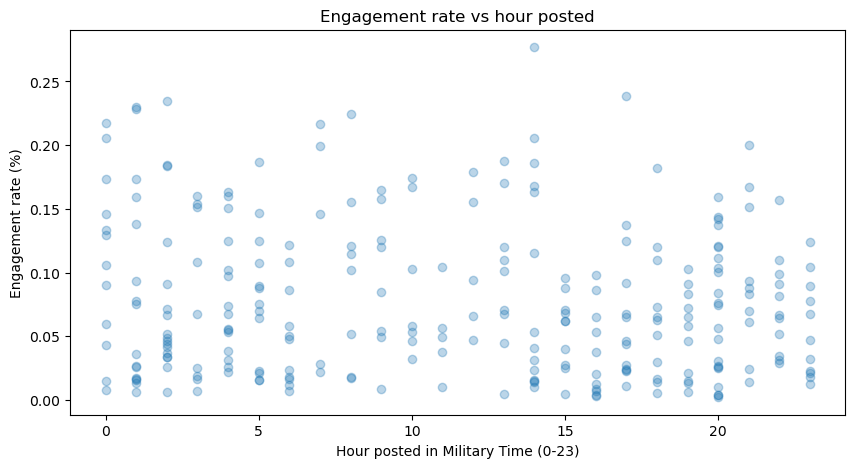

In [214]:
#engagement v. hour posted

plt.figure(figsize=(10, 5))
plt.scatter(tiktok_df['hour'], tiktok_df['engagement_rate'], alpha=0.3)
plt.xlabel('Hour posted in Military Time (0-23)')
plt.ylabel('Engagement rate (%)')
plt.title('Engagement rate vs hour posted')
plt.show()

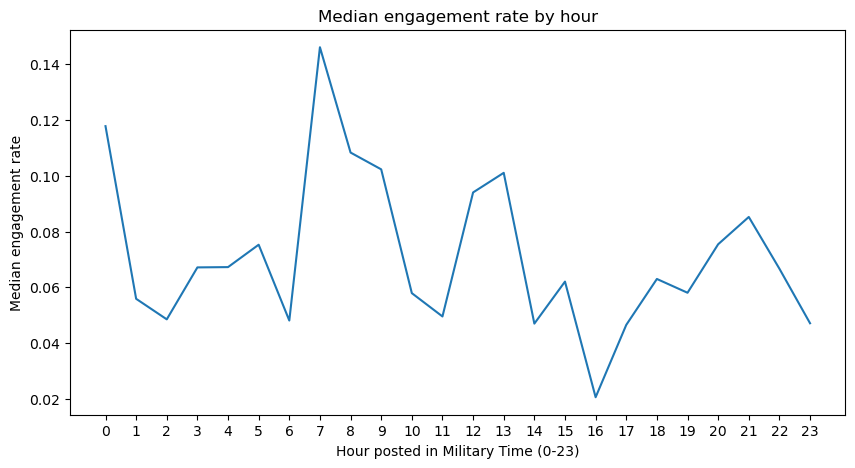

In [215]:
#engagement rate by hour

by_hour = tiktok_df.groupby('hour')['engagement_rate'].median()

plt.figure(figsize=(10, 5))
plt.plot(by_hour.index, by_hour.values)
plt.xlabel('Hour posted in Military Time (0-23)')
plt.ylabel('Median engagement rate')
plt.title('Median engagement rate by hour')
plt.xticks(range(0, 24))
plt.show()

In [216]:
print(tiktok_df['hour'].corr(tiktok_df['engagement_rate']))
#correlation number from -1 to 1. 
    #Near 0 = no straight-line relationship between the hour and engagement rate
    #Near 1 means later hours go with higher engagement, and near -1 means the opposite.

-0.12244193015286824


In [217]:
print(tiktok_df['hour'].corr(tiktok_df['engagement_rate'], method='spearman'))

-0.08905517674195348


In [218]:
print(tiktok_df.groupby('year')[['hour', 'engagement_rate']].corr().iloc[0::2, -1])

year      
2022  hour    0.155418
2023  hour   -0.077399
2024  hour   -0.223490
2025  hour   -0.342676
Name: engagement_rate, dtype: float64


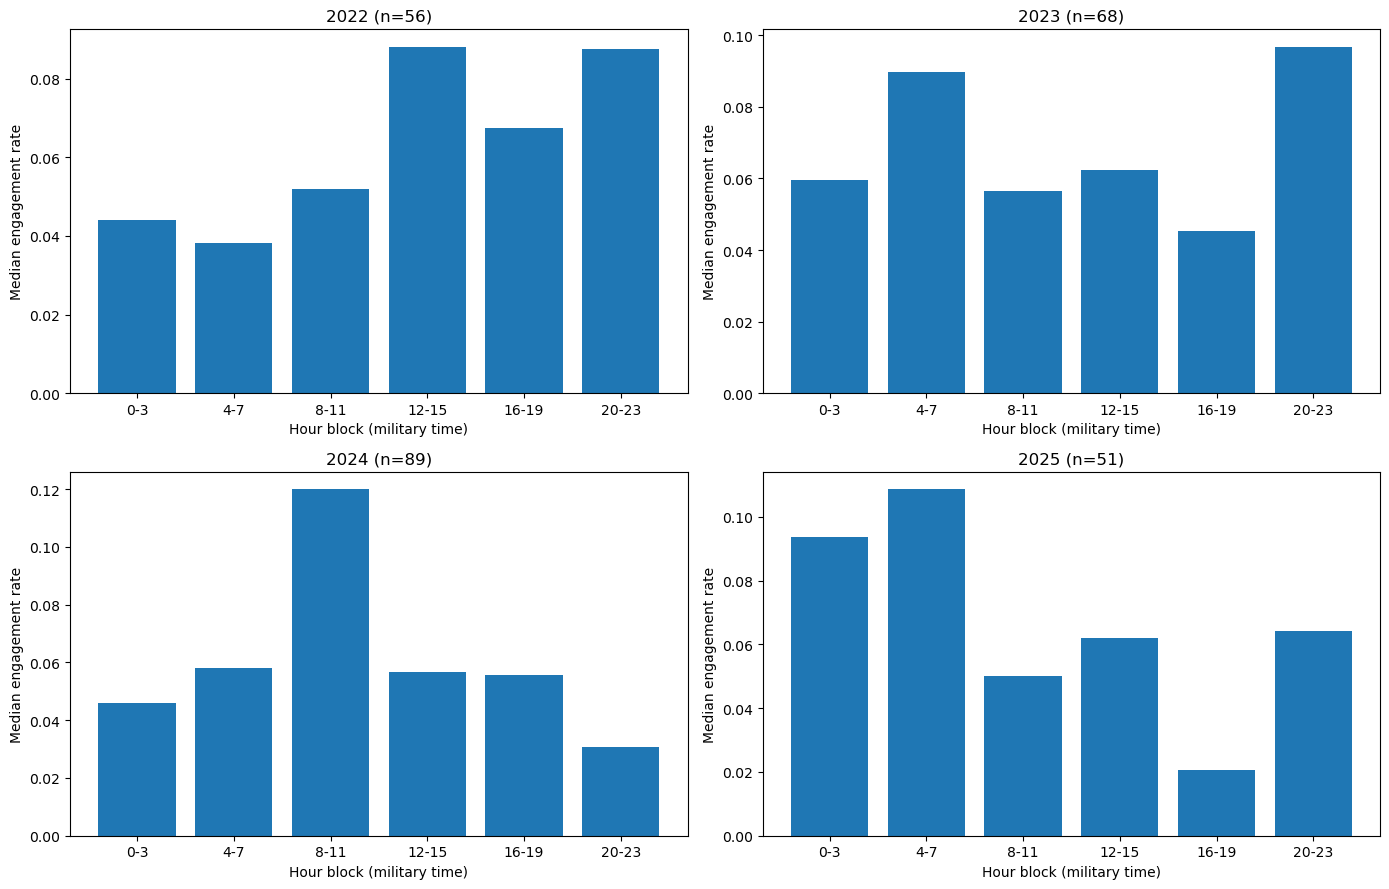

In [235]:
#group hours into 4-hour blocks to make graphing easier
tiktok_df['hour_block'] = pd.cut(
    tiktok_df['hour'],
    bins=[-1, 3, 7, 11, 15, 19, 23],
    labels=['0-3', '4-7', '8-11', '12-15', '16-19', '20-23']
)

#one graph per year
fig = plt.figure(figsize=(14, 9))
years = [2022, 2023, 2024, 2025]

for i, year in enumerate(years, start=1):
    ax = fig.add_subplot(2, 2, i)
    data = tiktok_df[tiktok_df['year'] == year]
    med = data.groupby('hour_block', observed=False)['engagement_rate'].median()
    ax.bar(med.index.astype(str), med.values)
    ax.set_title(f'{year} (n={len(data)})')
    ax.set_xlabel('Hour block (military time)'
    ax.set_ylabel('Median engagement rate')

plt.tight_layout()
plt.savefig('images/engagement_by_block_year.png', dpi=150, bbox_inches='tight') 
plt.show()

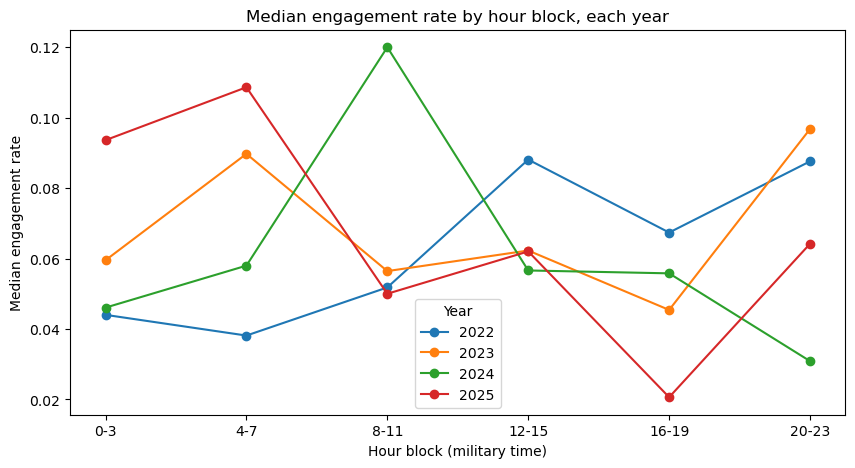

In [236]:
by_block_year = tiktok_df.groupby(['hour_block', 'year'], observed=False)['engagement_rate'].median().unstack()

by_block_year.plot(marker='o', figsize=(10, 5))
plt.xlabel('Hour block (military time)')
plt.ylabel('Median engagement rate')
plt.title('Median engagement rate by hour block, each year')
plt.legend(title='Year')
plt.savefig('images/engagement_by_block_year.png', dpi=150, bbox_inches='tight')
plt.show()

In [221]:
print(tiktok_df.groupby('hour_block', observed=False)['engagement_rate'].agg(['count', 'median']))

            count    median
hour_block                 
0-3            54  0.066937
4-7            44  0.065964
8-11           28  0.071171
12-15          38  0.067863
16-19          46  0.048823
20-23          54  0.072437


In [222]:
#Kruskal-Wallis

from scipy.stats import kruskal

groups = [g['engagement_rate'].dropna() for _, g in tiktok_df.groupby('hour_block', observed=False)]
print(kruskal(*groups))

KruskalResult(statistic=np.float64(8.213119362599741), pvalue=np.float64(0.14487473920819383))


In [223]:
by_hour = tiktok_df.groupby('hour')['engagement_rate'].agg(['count', 'median'])
print(by_hour)

      count    median
hour                 
0        12  0.117790
1        16  0.055908
2        17  0.048544
3         9  0.067164
4        15  0.067268
5        13  0.075294
6        11  0.048120
7         5  0.146077
8         8  0.108325
9         8  0.102306
10        7  0.057937
11        5  0.049580
12        5  0.094033
13        9  0.101058
14       14  0.047014
15       10  0.062075
16       11  0.020634
17       13  0.046556
18       11  0.063017
19       11  0.058077
20       22  0.075456
21       10  0.085243
22       11  0.066687
23       11  0.047144


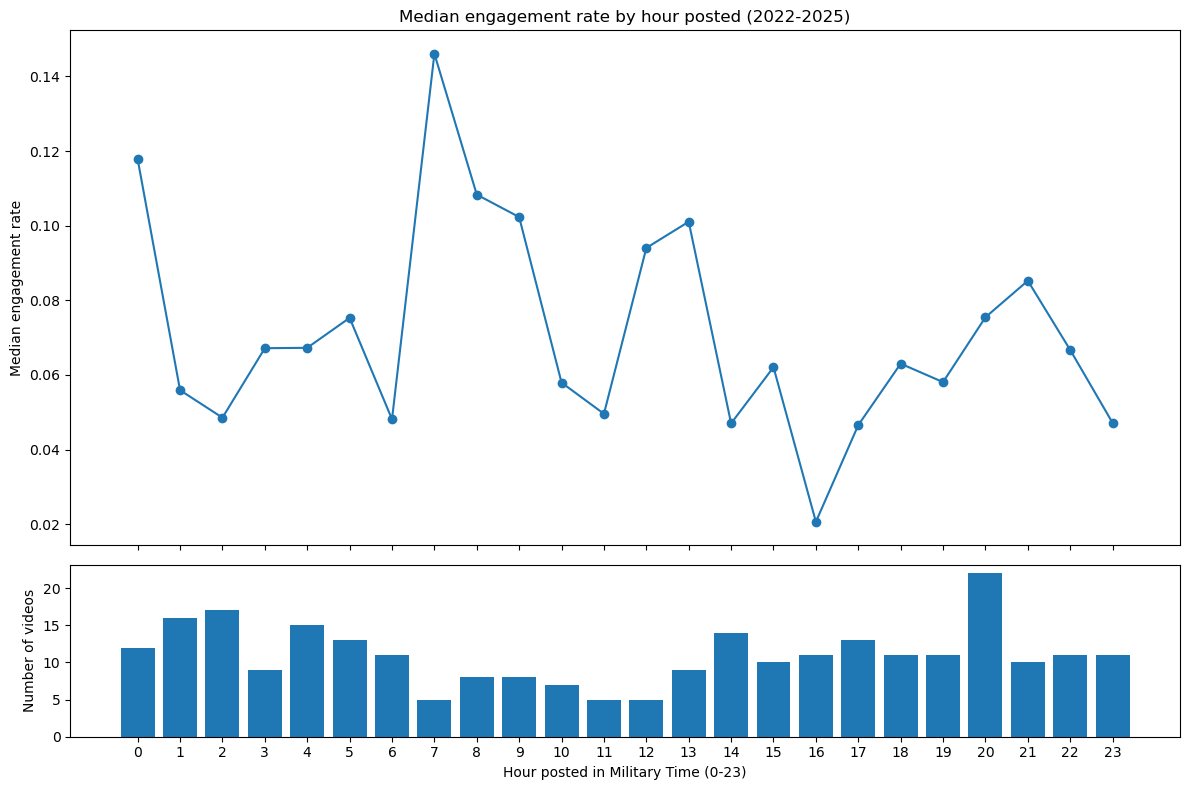

In [224]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True,
                               gridspec_kw={'height_ratios': [3, 1]})

by_hour = tiktok_df.groupby('hour')['engagement_rate'].agg(['count', 'median'])
by_hour = by_hour.reindex(range(24))   # puts every hour in, even empty ones

ax1.plot(by_hour.index, by_hour['median'], marker='o')
ax1.set_ylabel('Median engagement rate')
ax1.set_title('Median engagement rate by hour posted (2022-2025)')

ax2.bar(by_hour.index, by_hour['count'].fillna(0))
ax2.set_xlabel('Hour posted in Military Time (0-23)')
ax2.set_ylabel('Number of videos')
ax2.set_xticks(range(24))

plt.tight_layout()
plt.show()

In [225]:
from scipy.stats import kruskal

groups = [g['engagement_rate'].dropna() for _, g in tiktok_df.groupby('hour')]
print(kruskal(*groups))

KruskalResult(statistic=np.float64(25.66231272483151), pvalue=np.float64(0.31706475173732684))


In [226]:
#regression

tiktok_df['log_engagement'] = np.log(tiktok_df['engagement_rate'])
tiktok_df['log_followers'] = np.log(tiktok_df['author_followers'])
print(tiktok_df[['log_engagement', 'log_followers']].describe())

       log_engagement  log_followers
count      264.000000     264.000000
mean        -2.940054       9.403189
std          0.995377       2.774769
min         -6.104100       1.791759
25%         -3.656284       7.281902
50%         -2.728218       9.468665
75%         -2.188650      11.425721
max         -1.284349      15.955577


In [227]:
import statsmodels.formula.api as smf

model = smf.ols(
    "log_engagement ~ C(hour_block, Treatment('0-3')) + C(weekday) + C(year) + log_followers + duration_seconds",
    data=tiktok_df
).fit(cov_type='HC3')

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:         log_engagement   R-squared:                       0.057
Model:                            OLS   Adj. R-squared:                 -0.004
Method:                 Least Squares   F-statistic:                    0.9372
Date:                Wed, 25 Nov 2026   Prob (F-statistic):              0.527
Time:                        18:09:54   Log-Likelihood:                -365.08
No. Observations:                 264   AIC:                             764.2
Df Residuals:                     247   BIC:                             824.9
Df Model:                          16                                         
Covariance Type:                  HC3                                         
                                               coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------

In [228]:
from statsmodels.stats.anova import anova_lm

full = smf.ols("log_engagement ~ C(hour_block) + C(weekday) + C(year) + log_followers + duration_seconds",
               data=tiktok_df).fit()
reduced = smf.ols("log_engagement ~ C(weekday) + C(year) + log_followers + duration_seconds",
                  data=tiktok_df).fit()

print(anova_lm(reduced, full))

   df_resid         ssr  df_diff   ss_diff         F    Pr(>F)
0     252.0  253.502866      0.0       NaN       NaN       NaN
1     247.0  245.623129      5.0  7.879736  1.584781  0.164896


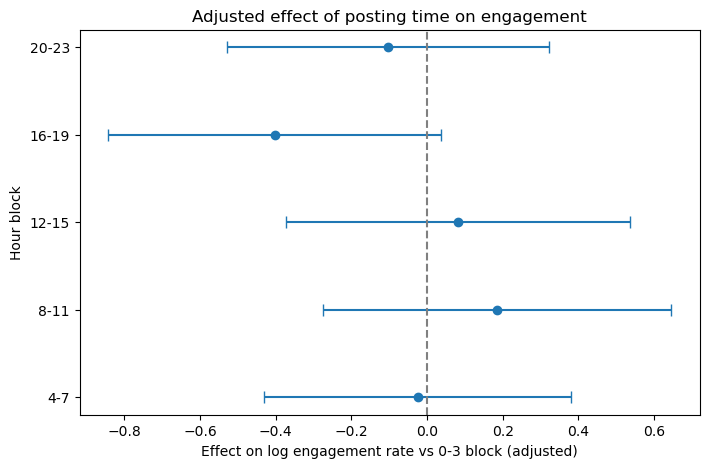

In [237]:
params = model.params.filter(like='hour_block')
ci = model.conf_int().loc[params.index]

labels = ['4-7', '8-11', '12-15', '16-19', '20-23']
plt.figure(figsize=(8, 5))
plt.errorbar(params.values, range(len(params)),
             xerr=[params.values - ci[0].values, ci[1].values - params.values],
             fmt='o', capsize=4)
plt.axvline(0, color='gray', linestyle='--')
plt.yticks(range(len(params)), labels)
plt.xlabel('Effect on log engagement rate vs 0-3 block (adjusted)')
plt.ylabel('Hour block')
plt.title('Adjusted effect of posting time on engagement')
plt.savefig('images/regression_hour_effects.png', dpi=150, bbox_inches='tight')
plt.show()

In [230]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=42)

for name, X in [('without hour', X_base), ('with hour', X_full)]:
    scores = cross_val_score(LinearRegression(fit_intercept=False), X, y, cv=cv, scoring='r2')
    print(name, 'average R-squared:', round(scores.mean(), 3))

without hour average R-squared: -0.088
with hour average R-squared: -0.123


In [231]:
import os
os.makedirs('images', exist_ok=True)
print(os.getcwd())

C:\Users\ambud\OneDrive\BIT3484


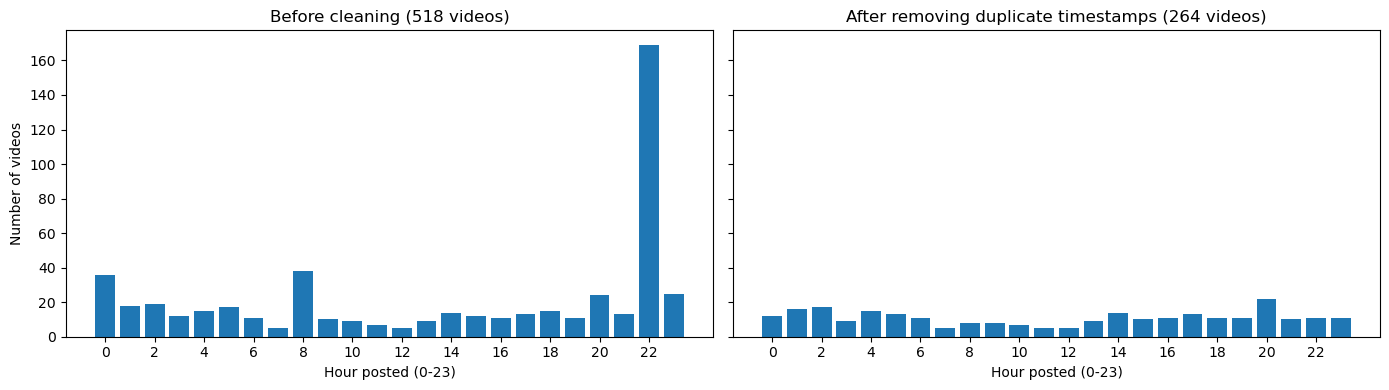

In [232]:
#added graph: data cleaning comparison

raw = pd.read_csv(tiktok_csv).drop(columns=['text_part', 'hashtags', 'id_sound'], errors='ignore').dropna()
raw['human_time'] = pd.to_datetime(raw['human_time'])
raw = raw[raw['human_time'].dt.year.between(2022, 2025)]

before = raw['human_time'].dt.hour.value_counts().reindex(range(24), fill_value=0)
after = tiktok_df['hour'].value_counts().reindex(range(24), fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
axes[0].bar(before.index, before.values)
axes[0].set_title(f'Before cleaning ({len(raw)} videos)')
axes[1].bar(after.index, after.values)
axes[1].set_title(f'After removing duplicate timestamps ({len(tiktok_df)} videos)')
for ax in axes:
    ax.set_xlabel('Hour posted (0-23)')
    ax.set_xticks(range(0, 24, 2))
axes[0].set_ylabel('Number of videos')
plt.tight_layout()
plt.savefig('images/hourly_counts_before_after.png', dpi=150, bbox_inches='tight')
plt.show()

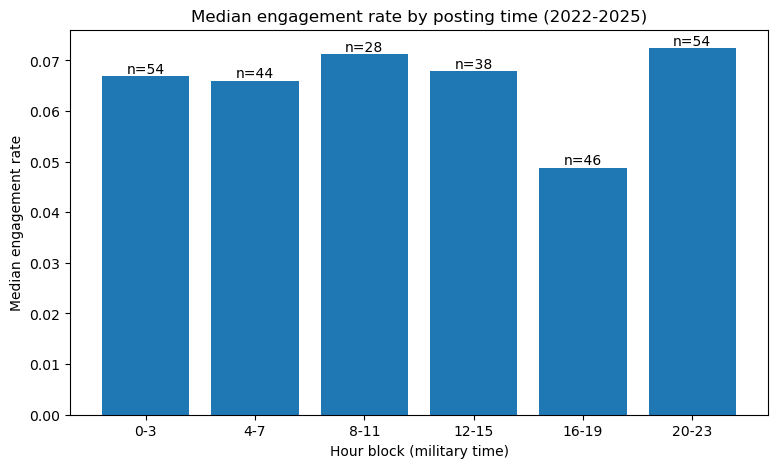

In [233]:
#added graph:
stats = tiktok_df.groupby('hour_block', observed=False)['engagement_rate'].agg(['count', 'median'])

plt.figure(figsize=(9, 5))
bars = plt.bar(stats.index.astype(str), stats['median'])
for bar, n in zip(bars, stats['count']):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'n={n}', ha='center', va='bottom')
plt.xlabel('Hour block (military time)')
plt.ylabel('Median engagement rate')
plt.title('Median engagement rate by posting time (2022-2025)')
plt.savefig('images/engagement_by_block.png', dpi=150, bbox_inches='tight')
plt.show()